# Laboratorio di Analisi Numerica
## Lezione 9

Cecilia Pagliantini <cecilia.pagliantini@unipi.it>  
Leonardo Robol <leonardo.robol@unipi.it>  
25-26 novembre 2026

*Aggiornamento da completare*

> **Quantità di esercizi:** in questa dispensa ci sono *più esercizi* di quanti uno studente medio riesca a farne durante una lezione di laboratorio, specialmente tenendo conto anche degli esercizi facoltativi. Questo perché è pensata per “tenere impegnati” per tutta la lezione anche quegli studenti che già hanno un solido background di programmazione.
>
> Quindi fate gli esercizi che riuscite, partendo da quelli *non* segnati come facoltativi, e non preoccupatevi se non li finite tutti!

Questa lezione di laboratorio è divisa in due parti: la prima verte sull'integrazione numerica, la seconda sulla risoluzione numerica di equazioni differenziali ordinarie. Si provino a completare almeno i primi esercizi di entrambe le parti.

Useremo `LinearAlgebra`, incluso nella libreria standard di Julia, e i pacchetti `Plots`, `Polynomials` e `NLsolve`. Se necessario, installate i pacchetti mancanti eseguendo una sola volta `using Pkg; Pkg.add(["Plots", "Polynomials", "NLsolve"])`.

Eseguite le celle dall'alto verso il basso e completate gli esercizi negli spazi predisposti. Le chiamate alle funzioni da scrivere sono commentate: togliete `#` dopo averle definite.

In [ ]:
using LinearAlgebra
using Plots
import Polynomials

## 1. Integrazione di funzioni

Scelti $a,b\in\mathbb{R}$ e una funzione reale $f$, vogliamo stimare numericamente l'integrale

$$S[f]=\int_a^b f(x)\,dx.$$

I metodi numerici per approssimare integrali vengono chiamati *metodi di quadratura*: ricevono in input una funzione e restituiscono un'approssimazione di $S[f]$. Qui ci occuperemo delle **formule di quadratura interpolatoria**.

### 1.1. Metodi interpolatori

Una larga classe di metodi di quadratura si ottiene con la seguente procedura:

1. Scegliamo $n+1$ nodi distinti $h_0,\ldots,h_n\in[a,b]$.
2. Calcoliamo il polinomio $p$ che interpola $f$ sui nodi, cioè $p(h_i)=f(h_i)$ per ogni $i=0,\ldots,n$. Che grado avrà questo polinomio?
3. Approssimiamo $S[f]$ con $S[p]$.

Prima di seguire questa strada dobbiamo scegliere il numero e la posizione dei nodi.

### 1.2. Le formule di Newton–Cotes

Per il momento assumiamo $a=0$, $b=1$. Una scelta naturale, fissato $n\geq1$, è prendere nodi equispaziati $h_i=i/n$, per $i=0,\ldots,n$.

Consideriamo $f(x)=\sin(4x)+4\log(1+x)$ e osserviamo come cambia il polinomio interpolante al variare di $n$.

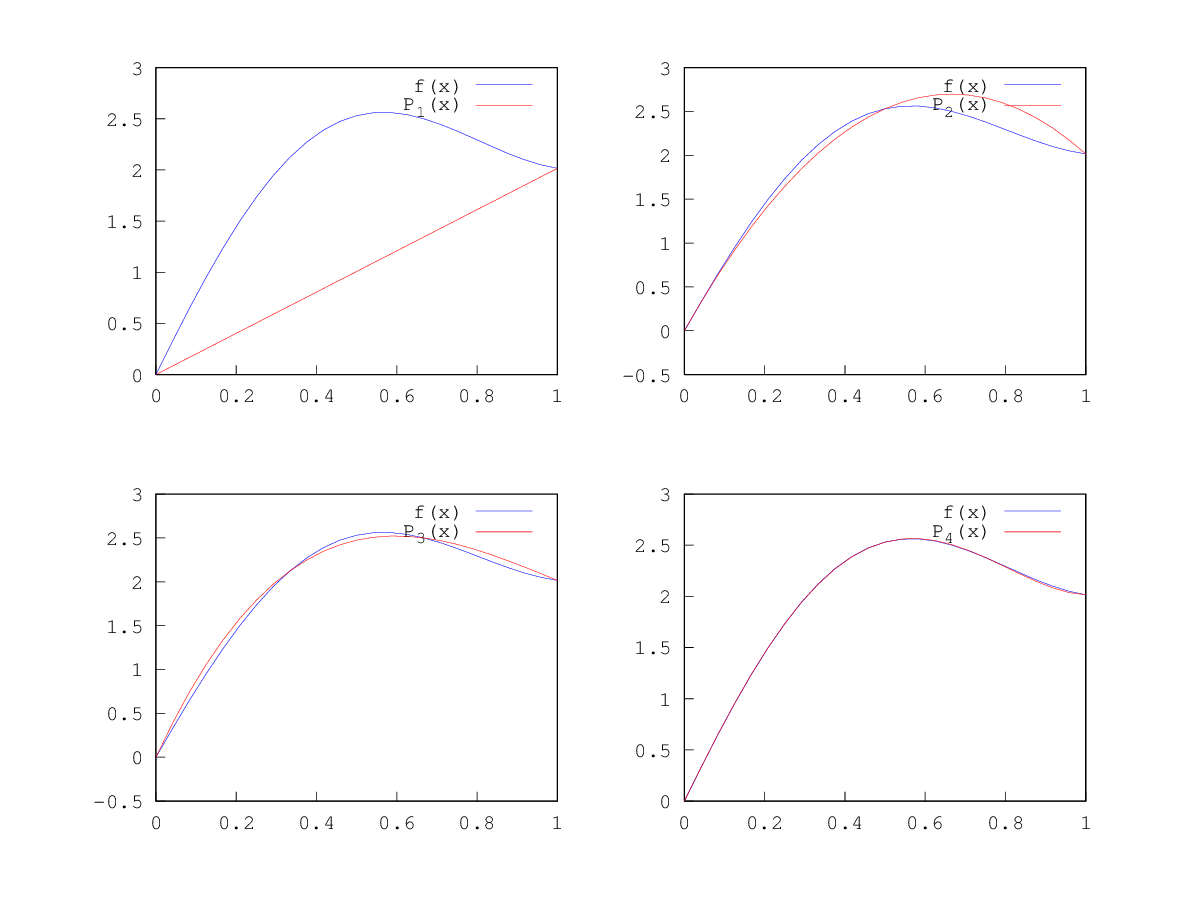

Interpolazione polinomiale di grado 1, 2, 3 e 4 (dispensa originale).

Il polinomio di grado $4$ è già una buona approssimazione di questa funzione. Se $p_j(x)=\sum_{i=0}^j a_i x^i$, possiamo integrarlo esattamente:

$$S[f]\approx S[p_j]=\int_0^1\sum_{i=0}^j a_i x^i\,dx
=\sum_{i=0}^j\frac{a_i}{i+1}.$$

**Julia:** al posto di `polyfit` di MATLAB usiamo `Polynomials.fit(x, y, n)`. Con $n+1$ nodi distinti e grado $n$ otteniamo il polinomio interpolante. `Polynomials.coeffs(p)` restituisce i coefficienti in **ordine crescente**: `[a₀, a₁, …, aₙ]`. Nella lezione 8 usavamo invece vettori in ordine decrescente: fate attenzione alla convenzione.

Per valutare una funzione su un vettore, usate il punto: `f.(x)`. Anche un polinomio del pacchetto si valuta come una funzione: `p(0.5)` oppure `p.(x)`.

Riferimento: [Polynomials.jl: costruzione, coefficienti e interpolazione](https://juliamath.github.io/Polynomials.jl/stable/).

In [ ]:
# Un esempio di interpolazione: il polinomio x² sui nodi 0, 1/2, 1.
nodi = collect(range(0, 1; length=3))
p = Polynomials.fit(nodi, nodi.^2, 2)
@show Polynomials.coeffs(p)
@show p(0.5);

### Esercizio 1

Consultate l'help di `Polynomials.fit` (in una cella separata, `?Polynomials.fit`) e scrivete una funzione `myquad(f, n)` che approssima l'integrale di `f` su $[0,1]$ usando $n+1$ nodi equispaziati e la formula precedente.

**Suggerimento:** se `c = Polynomials.coeffs(p)`, il coefficiente $a_i$ è `c[i+1]`. Il pacchetto può omettere coefficienti finali nulli; usate `length(c)` per scorrerli.

Verificate il codice sulla funzione $f(x)=\sin(4x)+4\log(1+x)$, sapendo che

$$S[f]=-4+\log(256)+\frac12\sin^2(2).$$

In [ ]:
# Scrivete qui la funzione myquad(f, n)

In [ ]:
fquad(x) = sin(4*x) + 4*log(1 + x)
integrale_esatto = -4 + log(256) + sin(2)^2 / 2
# q = myquad(fquad, 4)
# @show q abs(q - integrale_esatto)

**Julia:** una funzione può essere passata come argomento direttamente, per esempio `myquad(sin, 5)`. Le funzioni anonime si scrivono con `->`, per esempio `x -> 1 + x`. Non serve creare un file separato.

In [ ]:
# myquad(sin, 5)         # circa 0.459697555984820
# myquad(x -> 1 + x, 3) # circa 1.5

### Esercizio 2

Provate a integrare funzioni più “difficili”, come

$$f_1(x)=\left|x-\frac12\right|,\qquad f_2(x)=\sqrt{f_1(x)}.$$

Che problemi notate al crescere di $n$? Aiutatevi disegnando il grafico della funzione e del polinomio interpolante. Potete confrontare le approssimazioni con gli integrali esatti $S[f_1]=1/4$ e $S[f_2]=\sqrt{2}/3$.

In [ ]:
f1(x) = abs(x - 1/2)
f2(x) = sqrt(f1(x))
# Inserite qui gli esperimenti con myquad e i grafici dei polinomi interpolanti

### Esercizio 3 (facoltativo)

Come si potrebbe stimare la precisione di queste formule di quadratura usando lo sviluppo di Taylor? In che modo la regolarità richiesta giustifica il comportamento osservato nell'esercizio 2?

*Scrivete qui le dimostrazioni e le osservazioni per l’esercizio 3.*

### 1.3. Funzioni polinomiali a tratti

Aumentare il numero di nodi fa crescere il grado del polinomio. L'interpolazione su nodi equispaziati può diventare inaccurata, soprattutto per funzioni poco regolari; anche il calcolo dei coefficienti può risentire del condizionamento.

Una possibile soluzione è interpolare $f$ con una funzione polinomiale **a tratti di grado basso**. Dividiamo $[a,b]$ in $\ell$ sottointervalli $[x_i,x_{i+1}]$, per $i=0,\ldots,\ell-1$, con $x_0=a$ e $x_\ell=b$. Se $p_i$ interpola $f$ nel sottointervallo $i$,

$$\int_a^b f(x)\,dx
=\sum_{i=0}^{\ell-1}\int_{x_i}^{x_{i+1}}f(x)\,dx
\approx\sum_{i=0}^{\ell-1}\int_{x_i}^{x_{i+1}}p_i(x)\,dx.$$

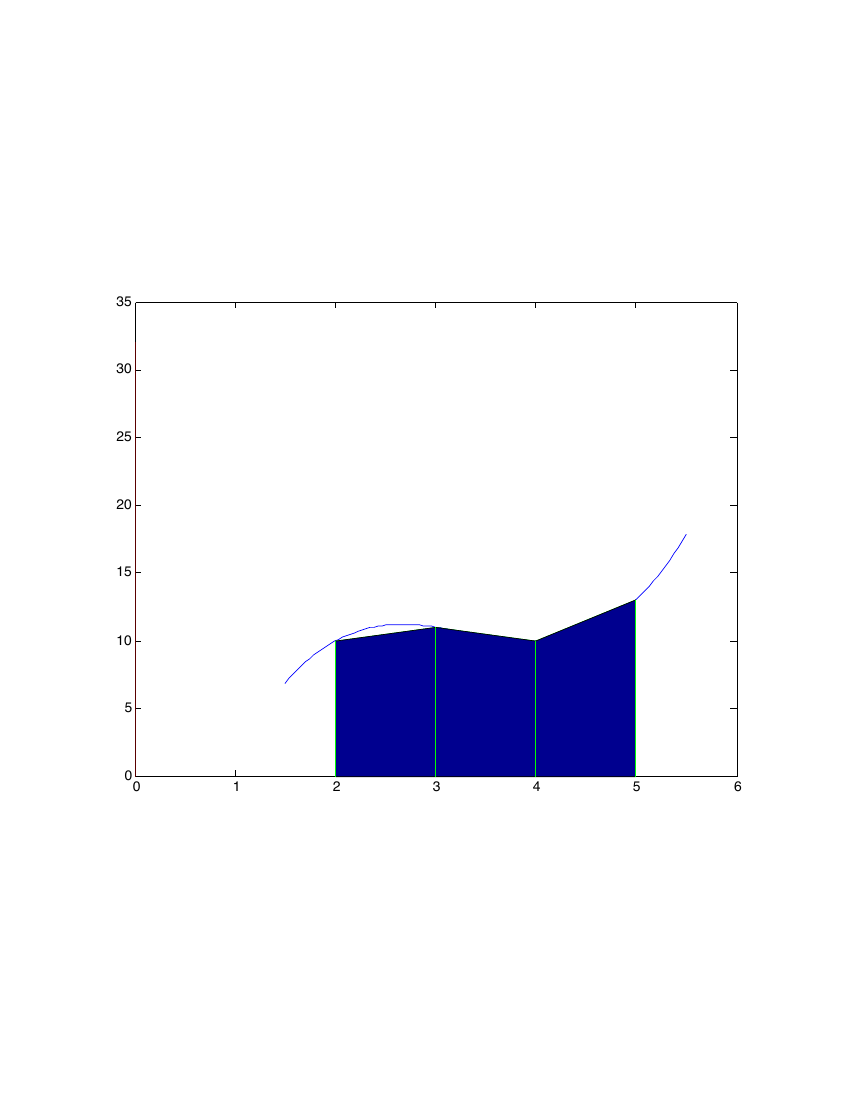

Integrazione mediante la formula dei trapezi (dispensa originale).

### Esercizio 4

Estendete `myquad(f, n)` aggiungendo due parametri per gli estremi: `myquad(f, n, a, b)`.

Potete integrare il polinomio su $[a,b]$, oppure usare il cambio di variabile $x=a+(b-a)s$ per ricondurvi a $[0,1]$:

$$\int_a^b f(x)\,dx=(b-a)\int_0^1 f\bigl(a+(b-a)s\bigr)\,ds.$$

In Julia le due funzioni possono coesistere perché hanno un numero diverso di argomenti. Verificate che su $[0,1]$ restituiscano lo stesso risultato.

In [ ]:
# Scrivete qui la funzione myquad(f, n, a, b)
# myquad(sin, 4, 0, pi)  # confrontate con 2

### Esercizio 5

Usando la nuova versione di `myquad`, scrivete una funzione `myquad2(f, a, b, k, n)` che divida $[a,b]$ in **$n$ sottointervalli** e applichi in ciascuno la formula di Newton–Cotes con polinomio di **grado $k$**, cioè con $k+1$ nodi.

Provate l'implementazione sulle funzioni $f_1$ e $f_2$ dell'esercizio 2. Confrontate l'aumento del grado su tutto l'intervallo con l'aumento del numero di sottointervalli a grado basso fissato. Quale approccio funziona meglio? Perché?

**Nota:** qui $k$ indica il grado, così che per $k=1$ si ottenga la **formula dei trapezi** illustrata sopra. Nella dispensa originale l'espressione “$k$ punti” è incoerente con questa convenzione.

In [ ]:
# Scrivete qui la funzione myquad2(f, a, b, k, n)
# Confrontate gli errori per f1 e f2, variando k e n

### Esercizio 6 (facoltativo)

Esplicitate la formula ottenuta applicando `myquad2` con $k=1$. Scrivete una funzione `trapezi(f, a, b, n)` che la implementi in modo più efficiente, usando solo $n+1$ valutazioni di $f$ sui nodi condivisi, invece delle $2n$ valutazioni di un'implementazione che tratta separatamente i $n$ sottointervalli.

Provate anche una versione con operazioni su vettori e confrontatela con `myquad2(f, a, b, 1, n)`.

In [ ]:
# Scrivete qui la funzione trapezi(f, a, b, n) e il confronto richiesto